# DBO trend maps that match the scorecard — chl (AO.emp), b$_{bp}$(443), a$_{dg}$(443)

Everything streams from OB.DAAC through `earthaccess`; nothing is downloaded
to disk except the small trend products this notebook writes at the end.

### Why this notebook exists

The published per-pixel trend maps did not agree with the Fig. 8 scorecard table, for three reasons:

| | old maps | scorecard table | here |
|---|---|---|---|
| temporal unit | **annual** per-pixel means (n ≈ 24) | monthly means → month-of-year anomaly (n ≈ 130–180) | **monthly anomaly** |
| deseasonalized | no | yes | **yes** |
| chl product | `reg_px` = AOReg.emp (regional) | Lewis & Arrigo **AO.emp** (pan-Arctic) | **AO.emp** |
| spatial unit | one pixel | box mean (10³–10⁴ pixels) | both, and they are compared |

Going from ~170 monthly anomalies to 24 annual means costs roughly an order of magnitude in sample
size, and the AR(1) correction then bites hard (chl DBO2 drops to n_eff ≈ 13, b$_{bp}$ DBO1 to
n_eff ≈ 8). That alone flipped the marginal cells — DBO2 chl and DBO1 b$_{bp}$ — from significant to
not, which is exactly the disagreement that prompted this rewrite.

### The estimator (identical at pixel scale and box scale)

1. composite → **monthly mean** (daily chl, 8-day a$_{dg}$, already-monthly b$_{bp}$);
2. subtract the **month-of-year climatology** (linear units, not log — this is the convention the
   scorecard row uses, and it reproduces the published numbers exactly);
3. **Theil–Sen** slope on decimal year, expressed as **%/decade of that pixel's (box's) record mean**;
4. **Mann–Kendall** p with the variance inflated by n_eff = n(1−φ)/(1+φ), φ = lag-1 autocorrelation
   of the trend residuals.

Steps 1–4 are run per pixel (on a stride, for speed) *and* per DBO box. §10 checks the box numbers
against the published scorecard values; §12 reports how often the pixel test and the box test agree.

### Figure

One stacked tri-panel: AO.emp chl, then b$_{bp}$(443), then a$_{dg}$(443). Dotted hatching = pixel
p < 0.05. **Thick orange box = that box's trend is significant** (the scorecard's test); thin black =
not. Hatching is hard to see at a glance, so the box outline carries the headline.

## 1. Imports

In [1]:
import time as _time, warnings, gc, pickle
from pathlib import Path
from datetime import date
import numpy as np, pandas as pd, xarray as xr
import earthaccess
from pyresample import AreaDefinition, geometry
from pyresample.kd_tree import resample_nearest
from matplotlib.path import Path as MplPath
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs, cartopy.feature as cfeature
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")
print("imports OK")

imports OK


## 2. Configuration

Grid, box corners and the L3m product ids are copied verbatim from `1_pull_data/03_modis-bbp443-monthly.ipynb`,
`1_pull_data/04_modis-adg443-8day.ipynb` and `1_pull_data/01_modis-aoemp-chl-daily.ipynb`, so the pixels here
are the same pixels those notebooks (and the scorecard) used.

`CHL_PERIOD` is the one real choice. `"DAY"` reproduces the scorecard definition exactly — monthly
means *of daily per-pixel chl* — at the cost of ~8,500 time steps × 3 bands. `"MO"` reads the monthly
Rrs composites instead (~280 steps × 3 bands, ~30× faster) and computes chl from month-mean Rrs;
because AO.emp is nonlinear in the band ratio that is a slightly different quantity (a Jensen bias),
which is fine for a first look but is *not* the table's definition. Start with `"MO"` if you just
want to see the figure, then re-run with `"DAY"` for the version that goes in the paper.

In [2]:
# ---------------------------------------------------------------- grid, region, boxes
# The scorecard's ocean-colour rows run 2002-2025, so the QC in section 10 only reproduces them if
# the record ends where theirs does. Set END_DATE = date.today() to extend the maps past 2025.
START_DATE, END_DATE = date(2002, 7, 1), date(2025, 12, 31)
DBO_BBOX = (-180.0, 50.0, -124.0, 74.0)      # coarse lon/lat pre-subset before regridding
ROI, N_WORKERS = 6_000, 8                     # nearest-neighbour radius (m); L3m is 4 km

dbo_area = AreaDefinition(
    "ease2_north_dbo_4km", "EASE-Grid 2.0 North: Aleutians -> Beaufort (DBO1-8), 4 km", "EPSG:6931",
    {"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0, "datum": "WGS84", "units": "m"},
    906, 845, (-3_624_000, 992_000, 0, 4_372_000))
ny, nx = dbo_area.shape
data_crs = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-152)
x0, y0, x1, y1 = dbo_area.area_extent

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}
SCORECARD_BOXES = ["DBO1", "DBO2", "DBO3", "DBO4", "DBO5"]   # the five columns of the table

# ---------------------------------------------------------------- products
RRS_CONCEPT = "C3380709369-OB_CLOUD"          # MODISA_L3m_RRS
IOP_CONCEPT = "C3380709177-OB_CLOUD"          # MODISA_L3m_IOP (GIOP), v2022.0
CHL_PERIOD  = "DAY"                            # "DAY" = scorecard definition | "MO" = ~30x faster first look
CHL_BANDS   = ["Rrs_443", "Rrs_488", "Rrs_547"]        # AO.emp needs only these three
AOEMP       = dict(a=0.0957, b=-2.7973, c=0.6581)      # Lewis & Arrigo (2020) AO.emp, pan-Arctic

# variable -> (concept, granule pattern, netCDF variable, panel label, unit label)
PRODUCTS = {
    "chl": (RRS_CONCEPT, None,                        None,      "chl $a$  (Lewis & Arrigo AO.emp)", "%/decade"),
    "bbp": (IOP_CONCEPT, "*.MO.IOP.bbp_443.4km.nc",   "bbp_443", "$b_{bp}$(443)  particles",         "%/decade"),
    "adg": (IOP_CONCEPT, "*.8D.IOP.adg_443.4km.nc",   "adg_443", "$a_{dg}$(443)  CDOM + detritus",   "%/decade"),
}
VARS = ["chl", "bbp", "adg"]                   # panel order, top to bottom

# ---------------------------------------------------------------- analysis knobs
STRIDE     = 5      # trend is fit on every STRIDE-th pixel and painted over the SxS block (4 km -> 20 km)
MIN_MONTHS = 60     # monthly anomalies required before a pixel is trended
MIN_YEARS  = 15     # ... and they must span at least this many years
SIG        = 0.05

# ---------------------------------------------------------------- figure knobs
# Display window. The grid runs to 50N, but south of ~59N is Gulf of Alaska: cropping it roughly
# doubles the scale of the DBO boxes, which is the whole point of the figure.
EXTENT   = (-179, -124, 59, 74)
FIG_W    = 16                        # panel height follows from the projected aspect (see the figure cell)
FS_TITLE, FS_CBAR, FS_TICK, FS_GRID, FS_BOX, FS_LEG = 26, 22, 19, 16, 16, 18
# box name placement: (dlon, dlat) from the box's top vertex. DBO5 is lifted because DBO4/5/6 sit
# almost on one line along the Beaufort coast and their labels would otherwise touch.
LABEL_NUDGE = {"DBO4": (-0.8, 0.15), "DBO5": (0.0, 0.95), "DBO6": (0.8, 0.15)}
SIG_BOX_COLOR, SIG_BOX_LW = "#ff6f00", 4.0     # orange + thick == this box's trend is significant
# significance stipple (per-pixel p_adj < SIG): marker size (pt^2), face/edge colours, edge width,
# and thinning (1 = every 20 km block, 2 = every other block)
SIG_DOT_SIZE, SIG_DOT_FACE, SIG_DOT_EDGE, SIG_DOT_EDGE_LW, SIG_DOT_EVERY = 14, "white", "black", 0.5, 1
NS_BOX_COLOR,  NS_BOX_LW  = "#111111", 1.2

# Reuse what already exists. The box series are the expensive-to-rebuild, cheap-to-store half, and
# they are already on disk in two places; the per-pixel monthly means are in neither, because every
# earlier notebook accumulated ANNUAL per-pixel sums, and an annual sum cannot be split back into
# months. So: box series free, pixel maps re-streamed.
REUSE_BOX_SERIES = True
BOX_CSV_DIR = Path.home() / "ADD_YOUR_PATH" / "scorecard" / "box_series"   # {var}_box_series.csv  # add your path
LEGACY_CKPT = {          # fallback: the streaming checkpoints, {var: (path, key holding box means)}
    "chl": (Path.home() / "modis_LA_dbo_DAY_v2_ckpt.pkl", "chl_rows_e"),   # chl_rows_e = AO.emp  # add your path
    "bbp": (Path.home() / "modis_bbp_dbo_ckpt.pkl",       "box_rows"),  # add your path
    "adg": (Path.home() / "modis_adg_dbo_8d_ckpt.pkl",    "box_rows"),  # add your path
}
RUN_PIXEL = ["chl", "bbp", "adg"]      # drop names here to skip their (expensive) pixel stream

OUT_DIR  = Path.home() / "ADD_YOUR_PATH" / "modis"  # add your path
OUT_STEM = "dbo_trend_maps_monthly_anom_8-25"
CKPT_DIR = Path.home() / "replot_ckpt"; CKPT_DIR.mkdir(exist_ok=True)  # add your path
CHECKPOINT = True

# published the Fig. 8 scorecard values, for the QC in section 10: (%/dec, p_AR1)
SCORECARD = {
    "chl": {"DBO1": (12.5, 0.0045), "DBO2": (12.2, 0.0385), "DBO3": (10.7, 0.0170),
            "DBO4": (3.8, 0.4596),  "DBO5": (5.7, 0.3459)},
    "bbp": {"DBO1": (8.2, 0.020),   "DBO2": (0.9, 0.835),   "DBO3": (2.5, 0.263),
            "DBO4": (0.5, 0.891),   "DBO5": (-3.9, 0.421)},
    "adg": {"DBO1": (11.3, 0.108),  "DBO2": (13.9, 0.022),  "DBO3": (6.5, 0.246),
            "DBO4": (2.0, 0.708),   "DBO5": (3.8, 0.435)},
}

MONTHS = pd.period_range(START_DATE, END_DATE, freq="M")
MIDX   = {(p.year, p.month): i for i, p in enumerate(MONTHS)}
MOY    = np.array([p.month for p in MONTHS])
DECYR  = np.array([p.year + (p.month - 0.5) / 12.0 for p in MONTHS], float)
print(f"grid {dbo_area.shape} | {len(MONTHS)} months {MONTHS[0]} -> {MONTHS[-1]} | chl from {CHL_PERIOD} Rrs")

grid (845, 906) | 282 months 2002-07 -> 2025-12 | chl from DAY Rrs


## 3. Auth + granule search

In [3]:
auth = earthaccess.login(persist=True)

def _search(concept, pattern, limit=12000):
    for k in range(5):
        try:
            return earthaccess.search_data(concept_id=concept, granule_name=pattern,
                                           temporal=(START_DATE.isoformat(), END_DATE.isoformat()),
                                           count=limit)
        except Exception as ex:
            print("  retry:", str(ex)[:80]); _time.sleep(2 * (k + 1))
    raise RuntimeError(f"CMR search failed for {pattern}")

def _gdate(g, monthly):
    d = g.data_links()[0].rsplit("/", 1)[-1].split(".")[1].split("_")[0]
    return date(int(d[:4]), int(d[4:6]), 1 if monthly else int(d[6:8]))

# --- Rrs bands for AO.emp chl: keep only time steps that have all three bands
gran_chl = {}
for bn in CHL_BANDS:
    gs = _search(RRS_CONCEPT, f"*.{CHL_PERIOD}.RRS.{bn}.4km.nc")
    for g in gs:
        gran_chl.setdefault(_gdate(g, CHL_PERIOD == "MO"), {})[bn] = g
    print(f"  {bn}: {len(gs)} granules")
gran_chl = {d: bd for d, bd in gran_chl.items() if len(bd) == len(CHL_BANDS)}

# --- single-variable IOP products
gran = {"chl": gran_chl}
for v in ("bbp", "adg"):
    concept, pat, _, _, _ = PRODUCTS[v]
    gs = _search(concept, pat)
    gran[v] = {}
    for g in gs:
        gran[v].setdefault(_gdate(g, pat.startswith("*.MO")), g)
    print(f"  {v}: {len(gran[v])} time steps ({min(gran[v])} -> {max(gran[v])})")
print(f"  chl: {len(gran_chl)} time steps with all {len(CHL_BANDS)} bands "
      f"({min(gran_chl)} -> {max(gran_chl)})")

  Rrs_443: 10160 granules
  Rrs_488: 10160 granules
  Rrs_547: 10160 granules
  bbp: 282 time steps (2002-07-01 -> 2025-12-01)
  adg: 1081 time steps (2002-07-04 -> 2025-12-27)
  chl: 8561 time steps with all 3 bands (2002-07-04 -> 2025-12-31)


## 4. Readers — one granule → one array on the EASE-2 DBO grid

Same nearest-neighbour regrid the other notebooks use (`radius_of_influence = 6 km` onto a 4 km grid),
so a pixel here is the same pixel there.

In [4]:
def _read_l3m(f, var):
    """L3m global grid -> (lat1d, lon1d, values) inside DBO_BBOX; non-positive -> NaN."""
    with xr.open_dataset(f, engine="h5netcdf") as ds:
        vn  = var or [v for v in ds.data_vars if v.startswith("Rrs_")][0]
        lat = np.asarray(ds["lat"].values, float); lon = np.asarray(ds["lon"].values, float)
        lo0, la0, lo1, la1 = DBO_BBOX
        jl = np.where((lat >= la0) & (lat <= la1))[0]; il = np.where((lon >= lo0) & (lon <= lo1))[0]
        if jl.size == 0 or il.size == 0: return None
        sub = ds[vn].isel(lat=slice(int(jl[0]), int(jl[-1]) + 1), lon=slice(int(il[0]), int(il[-1]) + 1))
        v  = np.asarray(sub.values, float).squeeze()
        la = np.asarray(sub["lat"].values, float); lo = np.asarray(sub["lon"].values, float)
    return la, lo, np.where(v > 0, v, np.nan)      # Rrs and IOPs are both strictly positive here

def _to_grid(la, lo, v):
    lon2d, lat2d = np.meshgrid(lo, la); m = np.isfinite(v)
    if not m.any(): return np.full(dbo_area.shape, np.nan, np.float32)
    sw = geometry.SwathDefinition(lons=np.where(lon2d > 180, lon2d - 360, lon2d)[m], lats=lat2d[m])
    return resample_nearest(sw, v[m], dbo_area, radius_of_influence=ROI,
                            fill_value=np.nan, reduce_data=False).astype(np.float32)

def project_one(granule, var):
    f = earthaccess.open([granule], show_progress=False)[0]
    try: out = _read_l3m(f, var)
    finally:
        try: f.close()
        except Exception: pass
    if out is None: return np.full(dbo_area.shape, np.nan, np.float32)
    return _to_grid(*out)

def aoemp_chl(r443, r488, r547):
    """Lewis & Arrigo (2020) AO.emp — pan-Arctic empirical chl from MODIS max(443,488)/547."""
    R = np.log10(np.maximum(r443, r488) / r547)
    return 10 ** (AOEMP["a"] + AOEMP["b"] * R + AOEMP["c"] * R * R)

def project_chl(band_granules):
    """3 Rrs bands -> one AO.emp chl grid."""
    g = {bn: project_one(band_granules[bn], None) for bn in CHL_BANDS}
    chl = aoemp_chl(g["Rrs_443"], g["Rrs_488"], g["Rrs_547"]).astype(np.float32)
    return np.where(np.isfinite(chl) & (chl > 0), chl, np.nan)
print("readers ready")

readers ready


## 5. DBO box masks on the EASE-2 grid

In [5]:
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {n: MplPath([(lo, la) for la, lo in c] + [(c[0][1], c[0][0])])
                   .contains_points(grid_pts).reshape(lons2d.shape)
             for n, c in DBO_BOXES.items()}
for n, m in box_masks.items(): print(f"  {n}: {int(m.sum()):>6,} cells")

  DBO1:  2,412 cells
  DBO2:    605 cells
  DBO3:  2,561 cells
  DBO4:  1,293 cells
  DBO5:    351 cells
  DBO6:    739 cells
  DBO7:    773 cells
  DBO8:    760 cells


## 6. Trend estimator — one function, used for pixels and for boxes

`theilsen_mk_ar1` is byte-for-byte the helper from the source notebooks, so any disagreement between
this notebook and the scorecard is a data/aggregation difference, never an estimator difference.

In [6]:
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def theilsen_mk_ar1(x, y, minn=8):
    """Theil-Sen slope (y-units/yr) + MK p, naive and AR(1)-variance-adjusted."""
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, p_naive=np.nan, p_adj=np.nan, phi=np.nan, n=n, n_eff=np.nan)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = (2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2 * n_eff + 5) / (9 * n_eff * (n_eff - 1))))))
             if n_eff > 4 else np.nan)
    return dict(slope=slope, p_naive=p_naive, p_adj=p_adj, phi=phi, n=n, n_eff=n_eff)

def monthly_anomaly(values):
    """values on the MONTHS axis -> month-of-year anomaly, in the same (linear) units."""
    v = np.asarray(values, float)
    clim = np.array([np.nanmean(v[MOY == m]) if np.isfinite(v[MOY == m]).any() else np.nan
                     for m in range(1, 13)])
    return v - clim[MOY - 1]

def trend_pct_per_decade(values):
    """The scorecard recipe on one monthly series: %/decade of the record mean + AR(1) MK p."""
    v = np.asarray(values, float); base = np.nanmean(v)
    if not np.isfinite(base) or base == 0: return dict(pct=np.nan, p_adj=np.nan, n=0, n_eff=np.nan, phi=np.nan)
    a = monthly_anomaly(v); ok = np.isfinite(a)
    if ok.sum() < MIN_MONTHS or (DECYR[ok].max() - DECYR[ok].min()) < MIN_YEARS:
        return dict(pct=np.nan, p_adj=np.nan, n=int(ok.sum()), n_eff=np.nan, phi=np.nan)
    r = theilsen_mk_ar1(DECYR[ok], a[ok])
    return dict(pct=r["slope"] * 10 / base * 100, p_adj=r["p_adj"], n=r["n"], n_eff=r["n_eff"], phi=r["phi"])

def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") if np.isfinite(p) else "n/a"
print("estimator ready")

estimator ready


## 7. Streaming — composite → per-pixel monthly means (+ per-box series)

One accumulator per variable: a `(month, y, x)` sum and count, folded as granules arrive. The count
is `uint16`, so the pair costs ~1.3 GB at 4 km for a 23-year record — process one variable at a time
and let the previous one go (§9 does that). The per-box series is folded in the same pass from the
native composites, which is how the scorecard's box series was built.

In [7]:
class MonthlyAccum:
    """Per-pixel monthly sums/counts + per-composite box means, checkpointable."""
    def __init__(self, name):
        self.name = name
        self.s = np.zeros((len(MONTHS), ny, nx), np.float32)
        self.c = np.zeros((len(MONTHS), ny, nx), np.uint16)
        self.box, self.done = {}, set()

    def fold(self, d, arr):
        i = MIDX.get((d.year, d.month))
        if i is None: return
        m = np.isfinite(arr)
        self.s[i][m] += arr[m]; self.c[i][m] += 1
        self.box[d] = {n: (float(np.mean(arr[mm])) if (mm := (mask & m)).any() else np.nan)
                       for n, mask in box_masks.items()}
        self.done.add(d)

    def means(self):
        """(month, y, x) monthly means; months with no observation are NaN."""
        out = self.s / np.maximum(self.c, 1)
        out[self.c == 0] = np.nan
        return out

    def box_monthly(self):
        """DataFrame indexed by month start: composite box means -> monthly box means."""
        df = pd.DataFrame(self.box).T.sort_index()
        df.index = pd.to_datetime(df.index)
        return df.resample("MS").mean()

    # --- checkpoint: the arrays are big, so write rarely (CKPT_EVERY below)
    def save(self):
        if not CHECKPOINT: return
        p = CKPT_DIR / f"{self.name}_{CHL_PERIOD if self.name == 'chl' else ''}"
        np.save(p.with_suffix(".s.npy"), self.s); np.save(p.with_suffix(".c.npy"), self.c)
        pickle.dump({"box": self.box, "done": self.done}, open(p.with_suffix(".meta.pkl"), "wb"))

    def load(self):
        p = CKPT_DIR / f"{self.name}_{CHL_PERIOD if self.name == 'chl' else ''}"
        if not (CHECKPOINT and p.with_suffix(".meta.pkl").exists()): return False
        self.s = np.load(p.with_suffix(".s.npy")); self.c = np.load(p.with_suffix(".c.npy"))
        meta = pickle.load(open(p.with_suffix(".meta.pkl"), "rb"))
        self.box, self.done = meta["box"], meta["done"]
        print(f"  resumed {self.name}: {len(self.done)} composites already folded")
        return True

def stream_variable(var, ckpt_every=1000):
    """Stream every composite of `var` onto the grid and fold it into a MonthlyAccum."""
    acc = MonthlyAccum(var); acc.load()
    items = sorted(d for d in gran[var] if d not in acc.done)
    if not items:
        print(f"{var}: nothing to stream ({len(acc.done)} composites already folded)"); return acc
    read = (lambda d: project_chl(gran["chl"][d])) if var == "chl" else \
           (lambda d, v=PRODUCTS[var][2]: project_one(gran[var][d], v))

    def _one(d):
        try: return d, read(d), None
        except Exception as e: return d, None, f"{type(e).__name__}: {str(e)[:60]}"

    t0 = _time.time(); nok = nfail = since = 0
    print(f"{var}: {len(acc.done)} done | streaming {len(items)} composites with {N_WORKERS} workers...")
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        src = iter(items); fs = set()
        for _ in range(N_WORKERS * 2):
            try: fs.add(ex.submit(_one, next(src)))
            except StopIteration: break
        while fs:
            dn, fs = wait(fs, return_when=FIRST_COMPLETED)
            for fut in dn:
                d, arr, err = fut.result()
                if arr is None:
                    nfail += 1
                    if nfail <= 8: print(f"   X {d} {err}")
                else:
                    acc.fold(d, arr); nok += 1; since += 1
                    if nok % 250 == 0:
                        print(f"   {nok}/{len(items)} ok, {nfail} fail ({(_time.time()-t0)/60:.1f} min)")
                    if since >= ckpt_every: acc.save(); since = 0
                try: fs.add(ex.submit(_one, next(src)))
                except StopIteration: pass
    acc.save()
    print(f"{var}: folded {nok} composites ({nfail} failed) in {(_time.time()-t0)/60:.1f} min")
    return acc
print("streamer ready")

streamer ready


### 7b. Box series without streaming

`{var}_box_series.csv` in `scorecard/box_series/` is the series the published table was computed
from — resampling it to months and running §6 on it reproduces the scorecard exactly. The streaming
checkpoints hold the same thing under `box_rows` (`chl_rows_e` for AO.emp chl), so either source
works and neither needs a network call. Loading the L&A checkpoint is the slow option: it also
carries the annual Rrs grids, so it is a multi-GB unpickle for a few hundred kB of series.

In [8]:
def load_box_series(var):
    """Monthly box means from disk: scorecard CSV first, streaming checkpoint second, else None."""
    if not REUSE_BOX_SERIES: return None
    csv = BOX_CSV_DIR / f"{var}_box_series.csv"
    if csv.exists():
        df = pd.read_csv(csv, parse_dates=["date"]).set_index("date")
        print(f"  {var}: box series from {csv.name} ({len(df)} composites)")
        return df.resample("MS").mean()
    path, key = LEGACY_CKPT.get(var, (None, None))
    if path and path.exists():
        print(f"  {var}: box series from {path.name} (large unpickle)...")
        d = pickle.load(open(path, "rb"))[key]
        df = pd.DataFrame(d).T.sort_index(); df.index = pd.to_datetime(df.index)
        return df.resample("MS").mean()
    print(f"  {var}: no saved box series - it will be folded from the stream")
    return None
print("box-series loader ready")

box-series loader ready


## 8. Per-pixel trends

The fit runs on every `STRIDE`-th pixel and the result is painted over the S×S block — a full 4 km
Theil–Sen over 765,000 pixels × ~170 months is hours of pairwise slopes for detail no one can see at
figure scale. Subsampling *first* also keeps the deseasonalization cheap: the climatology and the
anomaly are only ever formed on the strided stack (~30 MB), never on the full one.

In [9]:
def pixel_trends(stack, stride=None):
    """(month,y,x) monthly means -> (%/decade, p_AR1) on the full grid, fit on a stride."""
    S = stride or STRIDE
    sub = stack[:, ::S, ::S]                       # subsample first: everything below is cheap
    nys, nxs = sub.shape[1:]
    clim = np.stack([np.nanmean(sub[MOY == m], axis=0) if (MOY == m).any()
                     else np.full((nys, nxs), np.nan, np.float32) for m in range(1, 13)])
    anom = sub - clim[MOY - 1]
    base = np.nanmean(sub, axis=0)
    slope = np.full((nys, nxs), np.nan); padj = np.full((nys, nxs), np.nan)
    t0 = _time.time()
    for j in range(nys):
        for i in range(nxs):
            b = base[j, i]
            if not np.isfinite(b) or b == 0: continue
            a = anom[:, j, i]; ok = np.isfinite(a)
            if ok.sum() < MIN_MONTHS: continue
            if (DECYR[ok].max() - DECYR[ok].min()) < MIN_YEARS: continue
            r = theilsen_mk_ar1(DECYR[ok], a[ok])
            slope[j, i] = r["slope"] * 10 / b * 100        # %/decade of this pixel's record mean
            padj[j, i]  = r["p_adj"]
        if j % 25 == 0:
            print(f"   row {j}/{nys} ({(_time.time()-t0)/60:.1f} min)", end="\r")
    up = lambda a: np.kron(a, np.ones((S, S)))[:ny, :nx]   # paint each fit over its SxS block
    print(f"   fit {np.isfinite(slope).sum():,} of {slope.size:,} strided pixels "
          f"in {(_time.time()-t0)/60:.1f} min")
    return up(slope), up(padj)
print("pixel trend ready")

pixel trend ready


## 9. Run it — stream, trend, release

Each variable is streamed, trended and then dropped before the next one starts, so peak memory is one
monthly stack (~1.3 GB) rather than three. The trend maps and box series that survive are small.

Checkpoints are the monthly sum/count stacks themselves (~1.3 GB per variable at 4 km), written
every `ckpt_every` composites into `~/replot_ckpt/` — budget ~4 GB of scratch, or set
`CHECKPOINT = False` for the short bbp/adg runs.

Only the pixel maps stream. The box series (and therefore §10's scorecard check and the orange
boxes) come off disk via §7b, so you can run §10 immediately and see the box verdicts before
committing to any streaming at all. `RUN_PIXEL` controls which pixel maps are built — start with
`["bbp"]` (280 files) to prove the path end to end, then add `"adg"`, then `"chl"`.

**Runtime, 8 workers:** b$_{bp}$ ~10 min (280 monthly files), a$_{dg}$ ~40 min (1,050
8-day files), chl ~30 min with `CHL_PERIOD="MO"` and several hours with `"DAY"` (~8,500 days × 3
bands). The streams checkpoint, so a killed kernel resumes.

In [10]:
TREND, BOXSERIES = {}, {}
for v in VARS:
    BOXSERIES[v] = load_box_series(v)                     # free if it is already on disk
    if v not in RUN_PIXEL:
        print(f"{v}: pixel stream skipped (RUN_PIXEL = {RUN_PIXEL})")
        if BOXSERIES[v] is None:
            raise RuntimeError(f"{v}: no saved box series and no pixel stream - nothing to trend")
        continue
    acc = stream_variable(v)
    if BOXSERIES[v] is None: BOXSERIES[v] = acc.box_monthly()
    print(f"{v}: computing per-pixel trends (stride {STRIDE})...")
    TREND[v] = pixel_trends(acc.means())
    del acc; gc.collect()

if TREND:
    np.savez_compressed(OUT_DIR / f"{OUT_STEM}_trends.npz",
                        **{f"{v}_{k}": TREND[v][i] for v in TREND for i, k in enumerate(("slope", "p"))})
for v in VARS: BOXSERIES[v].to_csv(OUT_DIR / f"{OUT_STEM}_{v}_box_monthly.csv")
print(f"saved {len(TREND)} trend map(s) + {len(BOXSERIES)} monthly box series to {OUT_DIR}")

  chl: box series from modis_LA_dbo_DAY_v2_ckpt.pkl (large unpickle)...
chl: 0 done | streaming 8561 composites with 8 workers...
   250/8561 ok, 0 fail (2.2 min)
   500/8561 ok, 0 fail (4.5 min)
   750/8561 ok, 0 fail (6.6 min)
   1000/8561 ok, 0 fail (8.6 min)
   1250/8561 ok, 0 fail (11.0 min)
   1500/8561 ok, 0 fail (13.1 min)
   1750/8561 ok, 0 fail (15.1 min)
   2000/8561 ok, 0 fail (17.3 min)
   2250/8561 ok, 0 fail (19.7 min)
   2500/8561 ok, 0 fail (21.6 min)
   2750/8561 ok, 0 fail (23.7 min)
   3000/8561 ok, 0 fail (26.0 min)
   3250/8561 ok, 0 fail (28.2 min)
   3500/8561 ok, 0 fail (30.2 min)
   3750/8561 ok, 0 fail (32.6 min)
   4000/8561 ok, 0 fail (34.5 min)
   4250/8561 ok, 0 fail (36.7 min)
   4500/8561 ok, 0 fail (39.2 min)
   4750/8561 ok, 0 fail (41.3 min)
   5000/8561 ok, 0 fail (43.3 min)
   5250/8561 ok, 0 fail (45.9 min)
   5500/8561 ok, 0 fail (48.0 min)
   5750/8561 ok, 0 fail (50.1 min)
   6000/8561 ok, 0 fail (52.3 min)
   6250/8561 ok, 0 fail (54.7 min)
  

## 11. The figure — reload the saved per-pixel trends, set the style, draw (Fig. 2)

Runs without re-streaming once section 9 has written `*_trends.npz`.

In [17]:
z = np.load(OUT_DIR / f"{OUT_STEM}_trends.npz")
TREND = {v: (z[f"{v}_slope"], z[f"{v}_p"]) for v in VARS if f"{v}_slope" in z}
BOXSERIES = {v: pd.read_csv(OUT_DIR / f"{OUT_STEM}_{v}_box_monthly.csv", index_col=0, parse_dates=True)
             for v in VARS}
BOXRES = {v: {b: trend_pct_per_decade(BOXSERIES[v][b].reindex(MONTHS.to_timestamp()).values)
              for b in DBO_BOXES} for v in VARS}
print("reloaded — now re-run the figure cell in §11")

reloaded — now re-run the figure cell in §11


In [18]:
# ============================================================================
# STYLE — paste as its own cell, run once, then re-run the two figure cells.
# Overrides the constants in section 2 without re-running the whole config.
# ============================================================================
from matplotlib.ticker import MaxNLocator

EXTENT = (-179, -124, 59, 74)     # display window; crops the Gulf of Alaska so the boxes are bigger
FIG_W  = 16                       # panel height is derived from the projected aspect
FS_TITLE, FS_CBAR, FS_TICK, FS_GRID, FS_BOX, FS_LEG = 26, 30, 26, 16, 16, 22
# colorbar geometry: `aspect` is length/width, so SMALLER = fatter bar. Big type needs a fat bar.
CBAR_ASPECT, CBAR_SHRINK, CBAR_PAD, CBAR_NBINS = 11, 1.0, 0.015, 6

SIG_BOX_COLOR, SIG_BOX_LW = "#ffd400", 4.0   # yellow + thick == this box's trend is significant
SIG_BOX_HALO = "#2b2200"                     # dark casing: bare yellow vanishes on pale water/ice
NS_BOX_COLOR, NS_BOX_LW = "#111111", 1.2
# box name placement: (dlon, dlat) from the box's top vertex. DBO5 is lifted because DBO4/5/6 sit
# almost on one line along the Beaufort coast and their labels would otherwise touch.
LABEL_NUDGE = {"DBO4": (-0.8, 0.15), "DBO5": (0.0, 1.35), "DBO6": (0.9, 0.15)}
print("style constants set")


style constants set


chl: significant boxes -> ['DBO1', 'DBO2', 'DBO3']
bbp: significant boxes -> ['DBO1']
adg: significant boxes -> ['DBO2']
saved ~/ADD_YOUR_PATH/modis/dbo_trend_maps_monthly_anom_8-25.png
saved ~/ADD_YOUR_PATH/modis/dbo_trend_maps_monthly_anom_8-25.pdf


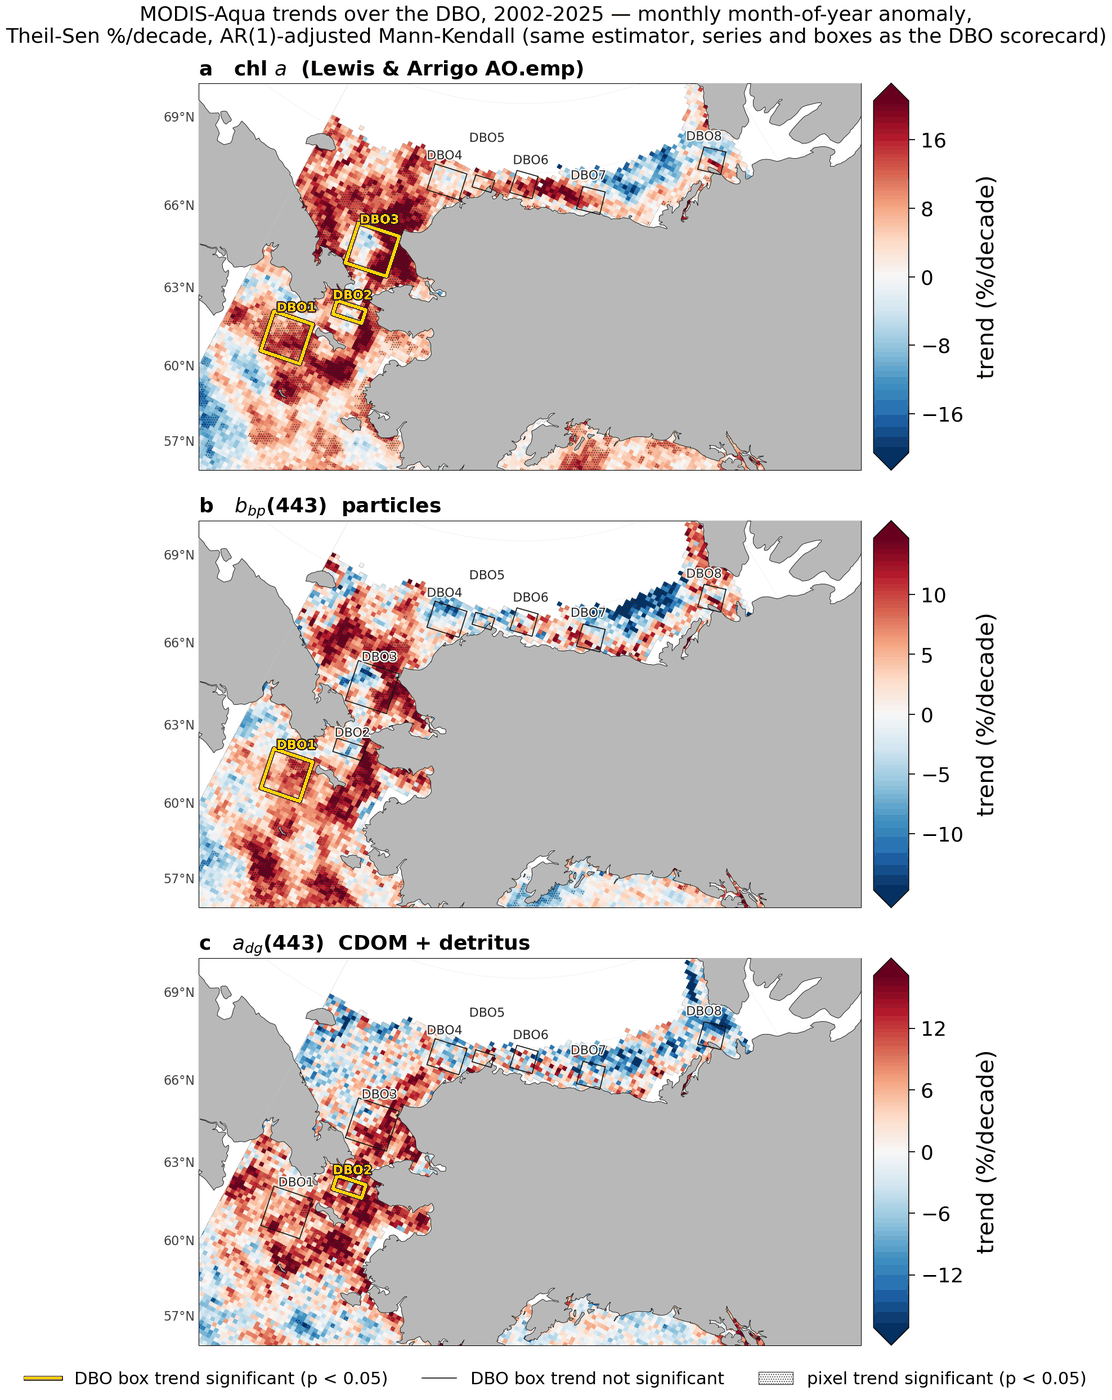

In [19]:
def _panel_aspect(extent, n=200):
    """Height/width of the projected display window — the figure has to be sized from this or the
    three map panels float in a sea of white space."""
    lo = np.linspace(extent[0], extent[1], n); la = np.linspace(extent[2], extent[3], n)
    LO, LA = np.meshgrid(lo, la)
    P = disp.transform_points(ccrs.PlateCarree(), LO.ravel(), LA.ravel())
    return (np.nanmax(P[:, 1]) - np.nanmin(P[:, 1])) / (np.nanmax(P[:, 0]) - np.nanmin(P[:, 0]))

def draw_panel(ax, var, slope, padj, sig_boxes, letter):
    vmax = max(float(np.nanpercentile(np.abs(slope), 98)), 1.0)
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    im = ax.imshow(slope, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                   vmin=-vmax, vmax=vmax, cmap="RdBu_r", zorder=1)

    # Significance stipple: one marker per STRIDE x STRIDE trend block (the fit is per block anyway).
    # contourf hatches render at a fixed screen density, so at print DPI they shrink to specks and the
    # dark-grey dots vanish on saturated red/blue. Explicit markers have a real size and a white face
    # with a dark edge, which reads on every colour. SIG_DOT_EVERY = 2 thins to every other block.
    sigmask = np.isfinite(padj) & (padj < SIG)
    xv, yv = dbo_area.get_proj_vectors()
    half, step = STRIDE // 2, STRIDE * SIG_DOT_EVERY
    jj, ii = np.meshgrid(np.arange(half, nx, step), np.arange(half, ny, step))
    keep = sigmask[ii, jj]
    ax.scatter(xv[jj[keep]], yv[ii[keep]], s=SIG_DOT_SIZE, marker="o",
               facecolor=SIG_DOT_FACE, edgecolor=SIG_DOT_EDGE, linewidths=SIG_DOT_EDGE_LW,
               transform=data_crs, zorder=4)

    ax.add_feature(cfeature.LAND, facecolor="0.72", zorder=5); ax.coastlines(lw=0.6, zorder=6)
    gl = ax.gridlines(draw_labels=True, lw=0.4, color="0.5", alpha=0.5, linestyle=":", zorder=7)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"size": FS_GRID, "color": "0.25"}

    for name, corners in DBO_BOXES.items():
        ring = corners + [corners[0]]
        hot = name in sig_boxes
        ln, = ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
                      color=SIG_BOX_COLOR if hot else NS_BOX_COLOR,
                      lw=SIG_BOX_LW if hot else NS_BOX_LW, zorder=9 if hot else 8,
                      solid_capstyle="round")
        if hot:   # yellow alone is too light to hold an edge against pale water — case it in dark
            ln.set_path_effects([pe.Stroke(linewidth=SIG_BOX_LW + 2.2, foreground=SIG_BOX_HALO), pe.Normal()])
        top = max(corners, key=lambda p: p[0])                     # label above the box's top vertex
        dlon, dlat = LABEL_NUDGE.get(name, (0.0, 0.15))
        t = ax.text(np.mean([p[1] for p in corners]) + dlon, top[0] + dlat, name,
                    transform=ccrs.PlateCarree(), ha="center", va="bottom",
                    fontsize=FS_BOX, fontweight="bold" if hot else "normal",
                    color=SIG_BOX_COLOR if hot else "0.15", zorder=10)
        t.set_path_effects([pe.Stroke(linewidth=3.2, foreground=SIG_BOX_HALO if hot else "white"),
                            pe.Normal()])

    ax.set_title(f"{letter}   {PRODUCTS[var][3]}", fontsize=FS_TITLE, fontweight="bold", loc="left", pad=10)
    cb = plt.colorbar(im, ax=ax, shrink=CBAR_SHRINK, aspect=CBAR_ASPECT, pad=CBAR_PAD, extend="both")
    cb.set_label(f"trend ({PRODUCTS[var][4]})", fontsize=FS_CBAR, labelpad=16)
    # fewer, rounder ticks: at 26 pt the default locator crowds the bar
    cb.locator = MaxNLocator(nbins=CBAR_NBINS, symmetric=True); cb.update_ticks()
    cb.ax.tick_params(labelsize=FS_TICK, length=8, width=1.3, pad=7)
    cb.outline.set_linewidth(1.1)
    return im

sig_boxes = {v: {b for b in DBO_BOXES
                 if np.isfinite(BOXRES[v][b]["p_adj"]) and BOXRES[v][b]["p_adj"] < SIG} for v in VARS}
for v in VARS: print(f"{v}: significant boxes -> {sorted(sig_boxes[v]) or 'none'}")

panel_h = FIG_W * 0.80 * _panel_aspect(EXTENT)          # 0.80 leaves room for the fatter colorbar column
panels = [v for v in VARS if v in TREND]
assert panels, "no pixel trend maps in memory - run section 9, or section 13 to reload them"
if len(panels) < len(VARS):
    print(f"note: only {panels} have pixel maps; the figure will have {len(panels)} panel(s)")
fig, axes = plt.subplots(len(panels), 1, figsize=(FIG_W, len(panels) * panel_h + 2.6),
                         subplot_kw={"projection": disp}, squeeze=False)
for ax, v, letter in zip(axes.ravel(), panels, "abc"):
    draw_panel(ax, v, *TREND[v], sig_boxes[v], letter)

_idx = BOXSERIES[VARS[0]].dropna(how="all").index
fig.suptitle(f"MODIS-Aqua trends over the DBO, {_idx.min():%Y}-{_idx.max():%Y} — monthly month-of-year anomaly,\n"
             "Theil-Sen %/decade, AR(1)-adjusted Mann-Kendall (same estimator, series and boxes as the DBO scorecard)",
             fontsize=FS_TITLE, y=0.995)
_key = Line2D([0], [0], color=SIG_BOX_COLOR, lw=SIG_BOX_LW, label="DBO box trend significant (p < 0.05)")
_key.set_path_effects([pe.Stroke(linewidth=SIG_BOX_LW + 2.2, foreground=SIG_BOX_HALO), pe.Normal()])
handles = [_key,
           Line2D([0], [0], color=NS_BOX_COLOR, lw=NS_BOX_LW, label="DBO box trend not significant"),
           Line2D([0], [0], linestyle="none", marker="o", markersize=max(np.sqrt(SIG_DOT_SIZE), 6),
                  markerfacecolor=SIG_DOT_FACE, markeredgecolor=SIG_DOT_EDGE, markeredgewidth=0.8,
                  label="pixel trend significant (p < 0.05)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=FS_LEG,
           bbox_to_anchor=(0.5, 0.004))
fig.subplots_adjust(top=0.94, bottom=0.045, left=0.045, right=0.995, hspace=0.13)

for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"{OUT_STEM}.{ext}", dpi=200, bbox_inches="tight")
    print("saved", OUT_DIR / f"{OUT_STEM}.{ext}")
plt.show()
